# 05 — Q4: tipos de interação × engajamento

**CRISP-DM, fases 4 e 5** · corresponde à seção **§7.2** de `docs/DOCUMENTACAO.md` e ao problema 1 da §13

> **Q4 — Quais tipos de interação ou atividades estão associados a maior engajamento dos estudantes?**

Neste notebook:
1. Como **não** medir: o índice “bruto” e a **associação mecânica** que ele cria (com demonstração)
2. Como medir: índice de **persistência** + correlação parcial controlando o volume + correção de Holm (passo a passo)
3. Resultados do ARES e do EdNet
4. Abandono pós-diagnóstico (dado descritivo)
5. Conclusão em quatro níveis e conferência com os resultados oficiais

In [1]:
import sys, json, warnings
from pathlib import Path

# encontra a raiz do projeto (pasta que contém src/config.py), venha o notebook de onde vier
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

import config as C
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)
print("Projeto:", ROOT)
from scipy import stats
from utils import spearman, partial_spearman, engagement_index, ajuste_multiplo, q4_tabela

a = pd.read_csv(C.PROCESSED / "ares_alunos.csv")
log = a[a["n_interacoes"] > 0].copy()                       # 192 alunos com log
ATIV = [c for c in log.columns if c.startswith("ativ::") and "Alertas" not in c]
total = log[ATIV].sum(axis=1)
print("Alunos:", len(log), "| atividades:", [c[6:] for c in ATIV])

Projeto: C:\Users\braia\OneDrive\Documentos\GitHub\Datasets-Beready


Alunos: 192 | atividades: ['Acesso (login)', 'Avaliação do texto (estrelas)', 'Leitura de textos', 'Navegação entre páginas', 'Outros (diálogos/botões)', 'Responder questões/tarefas', 'Turmas (entrar/sair)', 'Tutorial', 'Visualização de feedback/nota', 'Vocabulário (palavras e traduções)']


## 1. A primeira versão e o seu problema

**Primeira versão:**
- engajamento = média dos percentis de **nº de interações**, sessões, dias ativos e tempo;
- para cada atividade, correlação entre a **participação** dela (eventos da atividade ÷ total de interações do aluno) e esse índice.

O **total de interações aparece dos dois lados** da correlação: no índice e no denominador da participação.

In [2]:
log["I_bruto"] = engagement_index(log, ["n_interacoes", "n_sessoes", "dias_ativos", "tempo_estudo_min"])
bruto = {c[6:]: spearman(log[c] / total, log["I_bruto"], boot=0)["rho"] for c in ATIV}
pd.Series(bruto, name="ρ bruto (versão anterior)").sort_values().to_frame()

,ρ bruto (versão anterior)
Tutorial,-0.5586
Turmas (entrar/sair),-0.4395
Avaliação do texto (estrelas),-0.2178
Outros (diálogos/botões),-0.1125
Navegação entre páginas,-0.0922
Acesso (login),-0.0921
Responder questões/tarefas,0.0015
Leitura de textos,0.0862
Vocabulário (palavras e traduções),0.1562
Visualização de feedback/nota,0.3058


### 1.1 Por que o tutorial deu −0,56?

Todo aluno faz o tutorial um número **quase fixo** de vezes. A participação dele é ≈ **k ÷ total**: ela cai sozinha quando o total sobe, sem nenhum comportamento diferente.

Eventos de tutorial por aluno: mediana 3, quartis 3–4
ρ(contagem do tutorial, total)     = +0.17   ← o tutorial quase não varia com o uso
ρ(participação do tutorial, total) = -0.72   ← mas a participação cai com o total


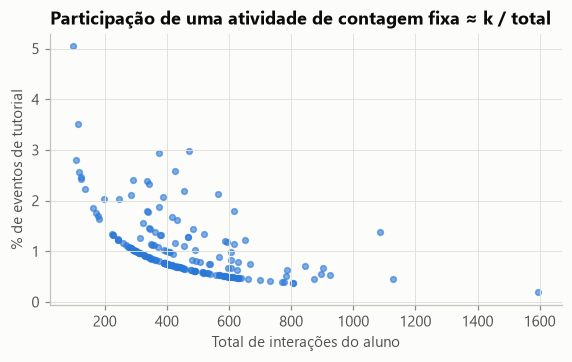

In [3]:
tut = log["ativ::Tutorial"]
print(f"Eventos de tutorial por aluno: mediana {tut.median():.0f}, quartis {tut.quantile(.25):.0f}–{tut.quantile(.75):.0f}")
print(f"ρ(contagem do tutorial, total)     = {stats.spearmanr(tut, total)[0]:+.2f}   ← o tutorial quase não varia com o uso")
print(f"ρ(participação do tutorial, total) = {stats.spearmanr(tut / total, total)[0]:+.2f}   ← mas a participação cai com o total")
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.scatter(total, tut / total * 100, s=14, color="#2a78d6", alpha=.6)
ax.set_xlabel("Total de interações do aluno"); ax.set_ylabel("% de eventos de tutorial")
ax.set_title("Participação de uma atividade de contagem fixa ≈ k / total")
plt.show()

### 1.2 Demonstração: uma atividade **falsa**

Criamos uma atividade inventada que **todo aluno faz exatamente 4 vezes**. Ela não distingue ninguém, e mesmo assim o método antigo diria que ela está “fortemente associada a baixo engajamento”:

In [4]:
falsa = pd.Series(4, index=log.index)
print(f"ρ bruto da atividade falsa (4 vezes para todos): {stats.spearmanr(falsa / total, log['I_bruto'])[0]:+.2f}")

ρ bruto da atividade falsa (4 vezes para todos): -0.77


➡️ O resultado do método antigo para atividades de contagem fixa é **artefato de cálculo**. O mesmo ocorre ao contrário com atividades que crescem junto com o volume, como a explicação do EdNet, que aparece após cada questão.

## 2. A versão corrigida

1. **Engajamento = persistência:** média dos percentis de **nº de sessões** e **dias ativos**, ou seja, o quanto o aluno *volta*. Não é a soma das atividades.
2. **Correlação parcial controlando log(total de interações):** *com o mesmo volume de uso, quem dedica uma parte maior a esta atividade volta mais vezes?*
3. **Correção de Holm** para os 10 testes. Sem ela, a chance de pelo menos um falso positivo seria 1 − 0,95¹⁰ ≈ **40%**.

In [5]:
log["I_persistencia"] = engagement_index(log, ["n_sessoes", "dias_ativos"])
print(f"Atividade falsa no método corrigido: ρ parcial = "
      f"{partial_spearman(falsa / total, log['I_persistencia'], np.log(log['n_interacoes']))['rho_parcial']:+.2f}  (← o artefato some)")

Atividade falsa no método corrigido: ρ parcial = -0.01  (← o artefato some)


### 2.1 Correção de Holm, passo a passo

Ordenam-se os p-valores do menor para o maior. O i-ésimo é multiplicado por (m − i + 1), com m = 10, e o resultado não pode ser menor que o anterior.

In [6]:
linhas = []
for c in ATIV:
    pc = partial_spearman(log[c] / total, log["I_persistencia"], np.log(log["n_interacoes"]))
    linhas.append({"atividade": c[6:], "ρ corrigido": pc["rho_parcial"], "p": pc["p"]})
t = pd.DataFrame(linhas).sort_values("p").reset_index(drop=True)
m = len(t)
t["multiplicador (m − i + 1)"] = m - t.index
t["p × multiplicador"] = (t["p"] * t["multiplicador (m − i + 1)"]).clip(upper=1)
t["p Holm (à mão)"] = t["p × multiplicador"].cummax()
t["p Holm (função)"] = ajuste_multiplo(t["p"])[0]
t["significativo após Holm"] = t["p Holm (à mão)"] < 0.05
t.round(4)

,atividade,ρ corrigido,p,multiplicador (m − i + 1),p × multiplicador,p Holm (à mão),p Holm (função),significativo após Holm
0,Leitura de textos,0.3143,0.0000,10,0.0001,0.0001,0.0001,True
1,Navegação entre páginas,0.2421,0.0007,9,0.0066,0.0066,0.0066,True
2,Acesso (login),0.1461,0.0438,8,0.3500,0.3500,0.3500,False
3,Visualização de feedback/nota,0.1407,0.0522,7,0.3656,0.3656,0.3656,False
4,Turmas (entrar/sair),-0.1228,0.0906,6,0.5435,0.5435,0.5435,False
5,Vocabulário (palavras e traduções),-0.0922,0.2048,5,1.0000,1.0000,1.0000,False
6,Avaliação do texto (estrelas),-0.0727,0.3173,4,1.0000,1.0000,1.0000,False
7,Tutorial,-0.0264,0.7166,3,1.0000,1.0000,1.0000,False
8,Responder questões/tarefas,-0.0240,0.7416,2,1.0000,1.0000,1.0000,False
9,Outros (diálogos/botões),-0.0045,0.9512,1,0.9512,1.0000,1.0000,False


## 3. Resultados

### 3.1 ARES (n = 192)

In [7]:
ta = q4_tabela(log, ATIV, total, "n_interacoes", label=lambda c: c[6:])
ta[["atividade", "rho_bruto", "rho_corrigido", "p_corrigido", "p_corrigido_holm", "pct_uso_alto_eng", "pct_uso_baixo_eng"]] \
    .sort_values("rho_corrigido", ascending=False).round(3)

,atividade,rho_bruto,rho_corrigido,p_corrigido,p_corrigido_holm,pct_uso_alto_eng,pct_uso_baixo_eng
9,Leitura de textos,0.086,0.314,0.000,0.000,100.0,100.0
8,Navegação entre páginas,-0.092,0.242,0.001,0.007,100.0,100.0
7,Acesso (login),-0.092,0.146,0.044,0.350,100.0,100.0
6,Visualização de feedback/nota,0.306,0.141,0.052,0.366,33.3,8.3
5,Outros (diálogos/botões),-0.112,-0.004,0.951,1.000,97.9,93.8
4,Responder questões/tarefas,0.002,-0.024,0.742,1.000,100.0,100.0
3,Tutorial,-0.559,-0.026,0.717,1.000,100.0,100.0
2,Avaliação do texto (estrelas),-0.218,-0.073,0.317,1.000,100.0,100.0
1,Vocabulário (palavras e traduções),0.156,-0.092,0.205,1.000,100.0,91.7
0,Turmas (entrar/sair),-0.440,-0.123,0.091,0.544,100.0,100.0


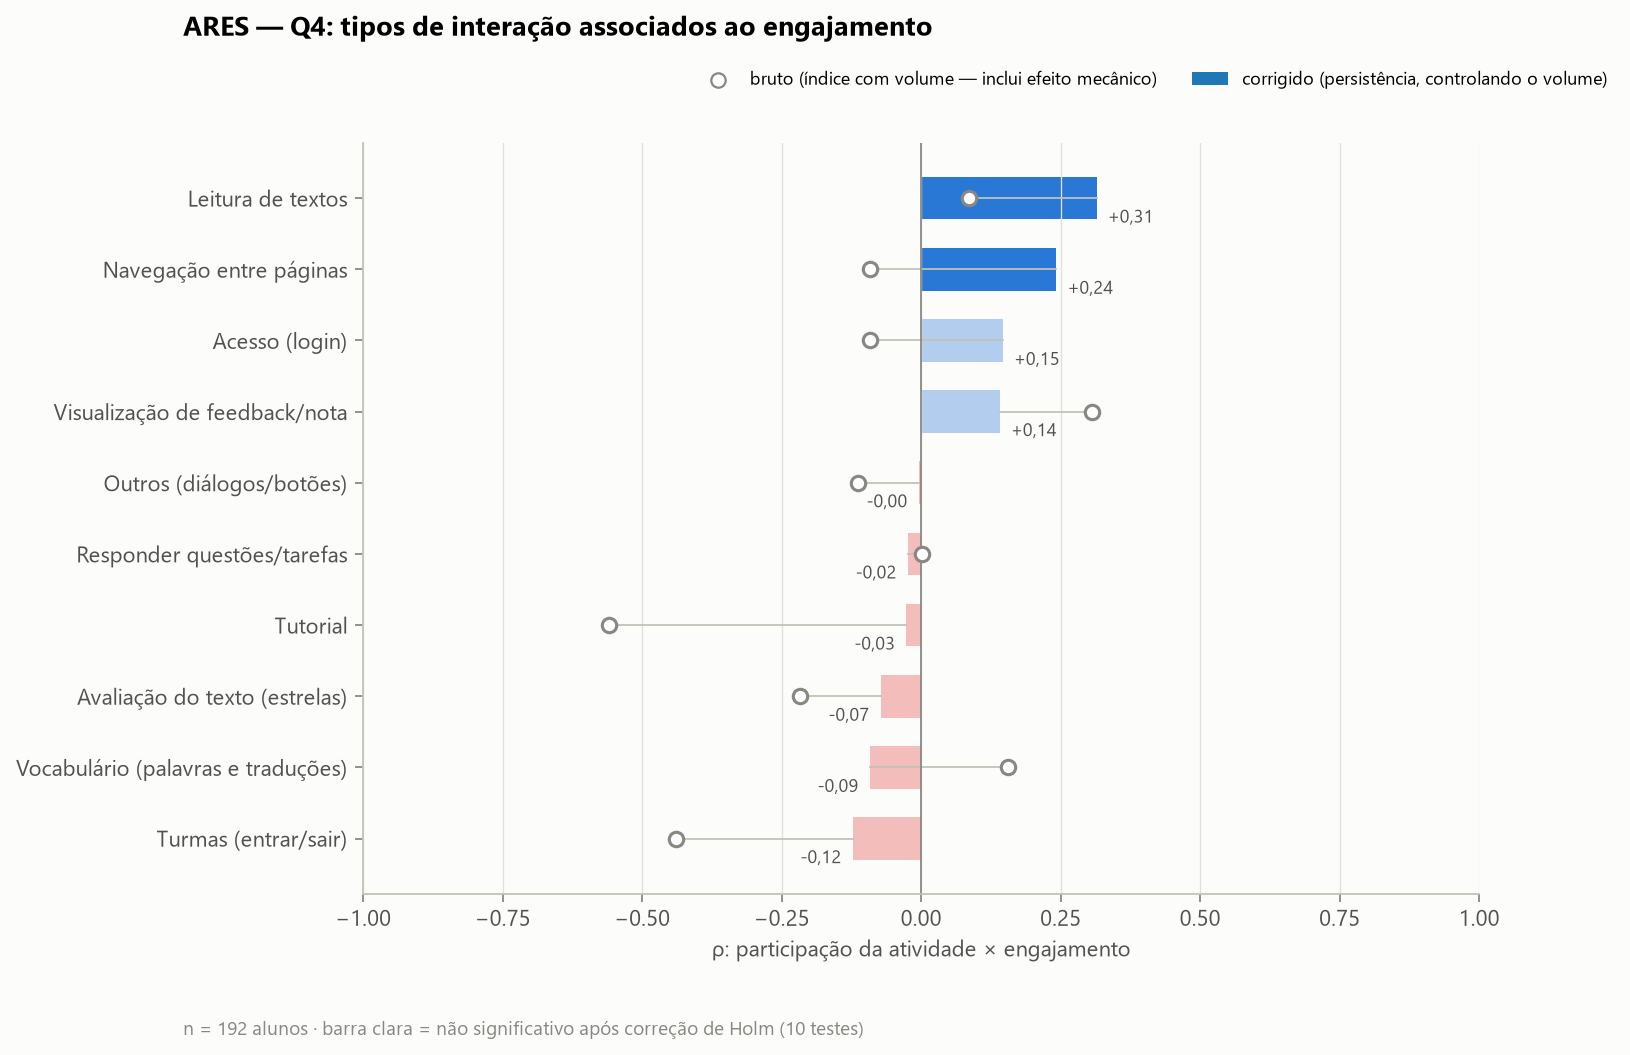

In [8]:
Image(filename=str(C.FIG / "ares" / "Q4_atividades_engajamento.png"))

Barra = ρ corrigido (clara = não significativa após Holm); ○ = ρ bruto (versão anterior). Só **leitura de textos** (+0,31) e **navegação** (+0,24) são significativas. O tutorial (−0,56 → −0,03) e o feedback (+0,31 → +0,14, ns) mudam completamente.

### 3.2 EdNet (n = 111.748 estudantes que foram além do diagnóstico)

In [9]:
SOURCES = {"sprint": "Prática por parte (sprint)", "diagnosis": "Diagnóstico inicial", "adaptive_offer": "Recomendação adaptativa",
           "review_quiz": "Quiz de revisão", "my_note": "Caderno de erros/anotações", "archive": "Questões salvas (arquivo)",
           "tutor": "Tutor", "review": "Revisão"}
ATIV_E = {f"src_{k}": v for k, v in SOURCES.items()} | {"acessos_explicacao": "Leitura de explicações (feedback)",
                                                        "acessos_aula": "Aulas (vídeo/texto)"}
u = pd.read_csv(C.PROCESSED / "ednet_users.csv.gz")
so_diag = u["n_eventos"] == u["src_diagnosis"]
ativos = u[~so_diag].copy()
te = q4_tabela(ativos, list(ATIV_E), ativos["n_eventos"], "n_eventos", label=lambda c: ATIV_E[c])
print("ρ(contagem de explicações, total de eventos):", round(stats.spearmanr(ativos["acessos_explicacao"], ativos["n_eventos"])[0], 2))
te[["atividade", "rho_bruto", "rho_corrigido", "p_corrigido_holm", "pct_uso_alto_eng", "pct_uso_baixo_eng"]] \
    .sort_values("rho_corrigido", ascending=False).round(3)

ρ(contagem de explicações, total de eventos): 0.99


,atividade,rho_bruto,rho_corrigido,p_corrigido_holm,pct_uso_alto_eng,pct_uso_baixo_eng
9,Aulas (vídeo/texto),0.566,0.244,0.0,85.3,8.8
8,Questões salvas (arquivo),0.419,0.240,0.0,52.6,3.9
7,Caderno de erros/anotações,0.310,0.174,0.0,71.5,18.2
6,Revisão,0.275,0.164,0.0,26.6,0.6
5,Tutor,0.241,0.153,0.0,22.3,0.6
4,Quiz de revisão,0.422,0.120,0.0,44.1,2.3
3,Recomendação adaptativa,0.647,0.090,0.0,88.3,8.9
2,Leitura de explicações (feedback),0.716,0.062,0.0,100.0,94.2
1,Diagnóstico inicial,-0.791,-0.097,0.0,84.6,92.8
0,Prática por parte (sprint),0.586,-0.109,0.0,98.6,83.6


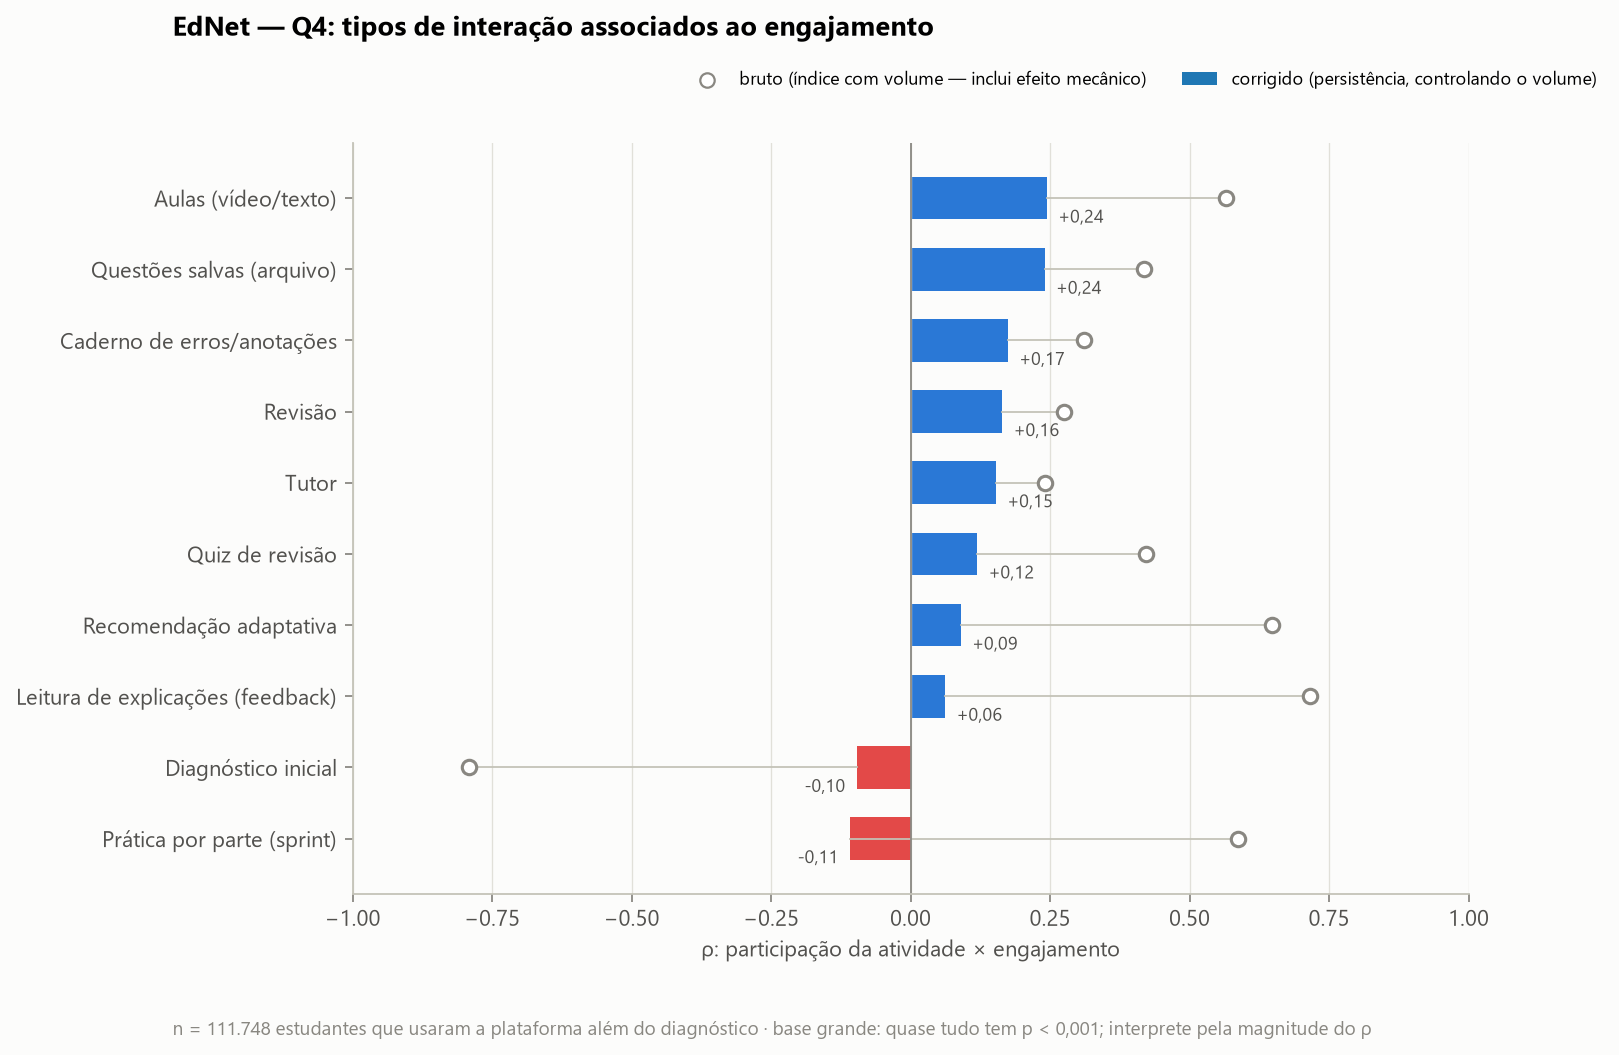

In [10]:
Image(filename=str(C.FIG / "ednet" / "Q4_atividades_engajamento.png"))

Com 111 mil estudantes, **todos** os ρ têm p < 0,001, inclusive os de 0,06. Aqui a significância não ajuda a separar nada: a leitura é pela **magnitude**. Aulas e questões salvas (+0,24) são as maiores, e são **fracas**. As explicações (+0,72 → +0,06) e a recomendação adaptativa (+0,65 → +0,09) só acompanhavam o volume.

In [11]:
mob = partial_spearman(ativos["pct_mobile"], engagement_index(ativos, ["n_sessoes", "dias_ativos"]), np.log(ativos["n_eventos"]))
print(f"Uso de mobile × engajamento (corrigido): ρ = {mob['rho_parcial']:+.3f} → desprezível (versão anterior: −0,14)")

Uso de mobile × engajamento (corrigido): ρ = +0.005 → desprezível (versão anterior: −0,14)


## 4. Observação descritiva: abandono logo após o diagnóstico (EdNet)

In [12]:
acc_diag = np.where(u["resp_diagnosis"] >= 5, u["acerto_diagnosis"] / u["resp_diagnosis"].clip(lower=1), np.nan)
print(f"Só fizeram o diagnóstico: {so_diag.sum():,} estudantes ({so_diag.mean():.1%})".replace(",", "."))
print(f"Acurácia no diagnóstico — abandonaram: {np.nanmean(acc_diag[so_diag]):.1%} | continuaram: {np.nanmean(acc_diag[~so_diag]):.1%}")
print(f"% de eventos em mobile — abandonaram: {u.loc[so_diag, 'pct_mobile'].mean():.1%} | continuaram: {u.loc[~so_diag, 'pct_mobile'].mean():.1%}")

Só fizeram o diagnóstico: 186.167 estudantes (62.5%)
Acurácia no diagnóstico — abandonaram: 46.3% | continuaram: 48.0%
% de eventos em mobile — abandonaram: 58.3% | continuaram: 83.3%


A acurácia no diagnóstico de quem abandonou é **quase igual** à de quem continuou: o desempenho no diagnóstico não parece explicar o abandono. Os dados **não** mostram o motivo, e isso é uma observação, não uma associação testada.

## 5. Conclusão da Q4

| | ARES (n = 192) | EdNet (n = 111.748) |
|---|---|---|
| **Observado** | Leitura de textos +0,31, navegação +0,24 (corrigido) | Aulas +0,24, questões salvas +0,24, caderno de erros +0,17, revisão +0,16; explicações +0,06 |
| **Significância** | Só leitura e navegação, após Holm | Todas p < 0,001 (efeito do n) |
| **Magnitude** | Moderada / fraca | Todas **fracas** ou desprezíveis |
| **Causa?** | Não. Alunos mais motivados podem tanto escolher mais conteúdo de estudo quanto voltar mais | Idem |

**Resposta:** depois de remover a associação mecânica, quem dedica mais do seu uso a **estudar conteúdo** (ler textos no ARES, ver aulas no EdNet) **tende a voltar mais vezes**, nas duas bases. “Ver feedback/explicação” e as atividades de entrada **não** são marcas fortes de engajamento, ao contrário do que a primeira versão indicava.

In [13]:
R_A = json.loads((C.TAB / "ares_resultados.json").read_text(encoding="utf-8"))
R_E = json.loads((C.TAB / "ednet_resultados.json").read_text(encoding="utf-8"))
of_a = {r["atividade"]: r for r in R_A["Q4"]["atividades"]}
of_e = {r["atividade"]: r for r in R_E["Q4"]["atividades"]}
linhas = [("ARES", r.atividade, of_a[r.atividade]["rho_corrigido"], r.rho_corrigido, of_a[r.atividade]["p_corrigido_holm"], r.p_corrigido_holm)
          for r in ta.itertuples()] + \
         [("EdNet", r.atividade, of_e[r.atividade]["rho_corrigido"], r.rho_corrigido, of_e[r.atividade]["p_corrigido_holm"], r.p_corrigido_holm)
          for r in te.itertuples()]
conf = pd.DataFrame(linhas, columns=["base", "atividade", "ρ oficial", "ρ notebook", "p Holm oficial", "p Holm notebook"])
conf["confere"] = np.isclose(conf["ρ oficial"], conf["ρ notebook"], atol=1e-4) & np.isclose(conf["p Holm oficial"], conf["p Holm notebook"], atol=1e-4)
display(conf.round(4))
assert conf["confere"].all()
print("✅ Os números deste notebook são os mesmos da documentação e dos resultados oficiais.")

,base,atividade,ρ oficial,ρ notebook,p Holm oficial,p Holm notebook,confere
0,ARES,Turmas (entrar/sair),-0.1228,-0.1228,0.5435,0.5435,True
1,ARES,Vocabulário (palavras e traduções),-0.0922,-0.0922,1.0000,1.0000,True
2,ARES,Avaliação do texto (estrelas),-0.0727,-0.0727,1.0000,1.0000,True
3,ARES,Tutorial,-0.0264,-0.0264,1.0000,1.0000,True
4,ARES,Responder questões/tarefas,-0.0240,-0.0240,1.0000,1.0000,True
5,ARES,Outros (diálogos/botões),-0.0045,-0.0045,1.0000,1.0000,True
6,ARES,Visualização de feedback/nota,0.1407,0.1407,0.3656,0.3656,True
7,ARES,Acesso (login),0.1461,0.1461,0.3500,0.3500,True
8,ARES,Navegação entre páginas,0.2421,0.2421,0.0066,0.0066,True
9,ARES,Leitura de textos,0.3143,0.3143,0.0001,0.0001,True


✅ Os números deste notebook são os mesmos da documentação e dos resultados oficiais.


**Próximo:** `06_Q5_evolucao.ipynb`.